# Test A/B -- campagne de retention des clients a risque

> **Avertissement.** Les donnees sont le jeu public IBM Telco Customer Churn.
> **Aucune campagne et aucune experience n'ont eu lieu.** Le groupe controle
> garde les vrais labels de churn ; **l'effet de la campagne sur le groupe
> traite est SIMULE**, avec des parametres explicites (reduction relative du
> churn). Aucun chiffre de ce notebook n'est un effet ou un gain reel : il
> montre comment concevoir, dimensionner, verifier et analyser un test A/B.

Fonctions : `src/ab_testing.py` (testees dans `tests/test_ab_testing.py`).
Modele et seuil : ceux du projet, lus sans modification
(`models/calibrated_model.pkl`, `models/serving_config.json`).

In [1]:
import json
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import ab_testing as ab
from src.train import RANDOM_STATE

T0 = time.time()
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# Parametres de l'etude (tous modifiables)
ALPHA = 0.05            # risque de premiere espece (faux positif)
POWER = 0.80            # puissance visee (1 - risque de seconde espece)
N_SIMS = 2000           # tirages pour le test A/A et la puissance simulee
SIMULATED_EFFECTS = [0.0, 0.10, 0.20, 0.30, 0.50]  # reductions relatives du churn SIMULEES
# Graines fixes, derivees de celle du projet (42) : une par usage.
SEED_ASSIGN, SEED_EFFECT, SEED_AA, SEED_POWER = (RANDOM_STATE + i for i in range(4))

## 1. Question metier

**Question** : une campagne de retention (une action commerciale par client)
envoyee aux clients que le modele juge a risque reduit-elle leur churn ?

- **H0** : la campagne ne change pas le taux de churn, p_traitement = p_controle.
- **H1** : la campagne change le taux de churn, p_traitement != p_controle.
  Le test est **bilateral** : une campagne peut aussi nuire (irriter des
  clients). On ne conclut a un effet utile que si la difference est
  significative **et** negative.
- **Metrique principale** (une seule, fixee avant le test) : taux de churn
  du groupe cible, controle contre traitement.
- **Garde-fou** : cout de la campagne (clients traites x cout d'une
  action), sous les hypotheses de cout du projet.

## 2. Population

Clients du jeu de test (20 % du jeu, jamais vus a l'entrainement) dont la
probabilite de churn du modele servi depasse le seuil du projet. Le seuil
est lu dans la configuration de l'API, pas recalcule. Si les artefacts
manquent : `python -m src.build_serving` (ils sont regeneres a l'identique).

In [2]:
config = json.loads((ROOT / "models" / "serving_config.json").read_text())
THRESHOLD = config["threshold"]
COSTS = config["costs_hypotheses"]
split = joblib.load(ROOT / "models" / "test_split.pkl")
model = joblib.load(ROOT / config["model_path"])

X_test, y_test = split["X_test"], split["y_test"].to_numpy().astype(int)
proba = model.predict_proba(X_test)[:, 1]
target = ab.target_mask(proba, THRESHOLD)

pop = X_test.loc[target].reset_index(drop=True)
y = y_test[target]
N_TARGET = len(y)
P_BASE = y.mean()
print(f"Modele : {config['model_path']} ; seuil : {THRESHOLD}")
print(f"Jeu de test : {len(y_test)} clients")
print(f"Groupe cible (probabilite >= {THRESHOLD}) : {N_TARGET} clients, "
      f"dont {y.sum()} churners -> taux de churn de base {P_BASE:.2%}")

Modele : models/calibrated_model.pkl ; seuil : 0.18
Jeu de test : 1409 clients
Groupe cible (probabilite >= 0.18) : 736 clients, dont 334 churners -> taux de churn de base 45.38%


Le taux de churn de base du groupe cible est bien plus eleve que celui du
jeu complet : c'est l'effet du ciblage par le modele.

## 3. Dimensionnement avant le test

On fixe **avant** de lancer le test : alpha = 5 %, puissance = 80 %, et
l'effet que l'on veut pouvoir detecter. La taille d'echantillon par groupe
vient de `statsmodels` (taille d'effet h de Cohen, test bilateral, groupes
de meme taille). Ici l'effectif est **impose** : le groupe cible (mesure en
section 2) est tout ce dont on dispose, soit environ la moitie par groupe. La question devient
donc aussi : quel est le plus petit effet detectable avec cet effectif ?

In [3]:
n_per_group = N_TARGET // 2
mde = ab.minimum_detectable_effect(P_BASE, n_per_group, ALPHA, POWER)
print(f"Effectif disponible : {n_per_group} clients par groupe")
print(f"Effet minimal detectable (alpha {ALPHA:.0%}, puissance {POWER:.0%}) : "
      f"churn {mde['p_control']:.1%} -> {mde['p_treatment']:.1%}, soit "
      f"{mde['absolute'] * 100:+.1f} points en absolu et une reduction relative de "
      f"{mde['relative_reduction']:.1%}")

sizing = pd.DataFrame([
    {"reduction_relative": r,
     "churn_traitement_vise": P_BASE * (1 - r),
     "n_requis_par_groupe": ab.required_sample_size(P_BASE, r, ALPHA, POWER),
     "n_disponible_par_groupe": n_per_group,
     "puissance_theorique_avec_n_disponible": ab.theoretical_power(P_BASE, r, n_per_group, ALPHA)}
    for r in SIMULATED_EFFECTS if r > 0
])
sizing["assez_grand"] = sizing["n_requis_par_groupe"] <= n_per_group
display(sizing)

Effectif disponible : 368 clients par groupe
Effet minimal detectable (alpha 5%, puissance 80%) : churn 45.4% -> 35.3%, soit -10.1 points en absolu et une reduction relative de 22.3%


,reduction_relative,churn_traitement_vise,n_requis_par_groupe,n_disponible_par_groupe,puissance_theorique_avec_n_disponible,assez_grand
0,0.1000,0.4084,1869,368,0.2375,False
1,0.2000,0.3630,459,368,0.7084,False
2,0.3000,0.3177,200,368,0.9677,True
3,0.5000,0.2269,67,368,1.0000,True


**Si l'echantillon est trop petit**, le test manque de puissance : un effet
reel mais plus petit que l'effet minimal detectable sera le plus souvent
**non significatif**. Ne pas rejeter H0 ne prouve alors **pas** que la
campagne est inutile ; cela dit seulement que le test ne pouvait pas le
voir. Les options : allonger la collecte (plus de clients sur plusieurs
mois), accepter de ne detecter que les gros effets, ou viser une metrique
plus sensible. Agrandir l'echantillon **apres** avoir vu les resultats
n'est pas une option (voir section 9).

## 4. Randomisation

Chaque client du groupe cible est tire au sort, independamment, avec une
probabilite de 1/2 d'etre traite (graine fixe). Deux verifications avant
toute analyse :
- **ratio d'echantillon** (SRM, *sample ratio mismatch*) : les tailles
  obtenues sont-elles compatibles avec 50/50 ? (chi-deux d'adequation) ;
  un ecart signale un probleme d'assignation ou de collecte ;
- **equilibre** sur l'anciennete, le contrat et le prix mensuel : ecart
  standardise (SMD, |SMD| < 0,1 est l'usage courant) et valeur p.

In [4]:
treated = ab.assign_groups(N_TARGET, SEED_ASSIGN)
srm = ab.srm_test(int((~treated).sum()), int(treated.sum()))
print(f"Controle : {srm['n_control']} ; traitement : {srm['n_treatment']} ; "
      f"chi-deux {srm['chi2']:.3f}, p = {srm['p_value']:.3f}")
print("Ratio conforme" if srm["p_value"] >= 0.01 else "ALERTE SRM : ne pas analyser avant d'expliquer l'ecart")

balance = ab.balance_table(pop, treated, numeric=["tenure", "MonthlyCharges"], categorical=["Contract"])
display(balance)

Controle : 371 ; traitement : 365 ; chi-deux 0.049, p = 0.825
Ratio conforme


,variable,level,control,treatment,smd,p_value
0,tenure,moyenne,18.8140,17.1808,-0.0904,0.2206
1,MonthlyCharges,moyenne,73.8272,71.1355,-0.1081,0.1429
2,Contract,Month-to-month,0.8841,0.9096,0.0839,0.5151
3,Contract,One year,0.1132,0.0877,-0.0850,0.5151
4,Contract,Two year,0.0027,0.0027,0.0009,0.5151


In [5]:
over = balance.loc[balance["smd"].abs() >= 0.1, ["variable", "level", "smd", "p_value"]]
print(f"|SMD| maximal : {balance['smd'].abs().max():.3f}")
print("Variables avec |SMD| >= 0,1 :", "aucune" if over.empty else over.to_dict("records"))

|SMD| maximal : 0.108
Variables avec |SMD| >= 0,1 : [{'variable': 'MonthlyCharges', 'level': 'moyenne', 'smd': -0.10811070618169938, 'p_value': 0.1429460184058015}]


**Lecture.** Avec une assignation aleatoire, un desequilibre leger sur une
variable est du au hasard (valeur p elevee) : sur quelques variables, il est
frequent qu'une depasse 0,1. La bonne reaction n'est **pas** de refaire le
tirage jusqu'a obtenir un equilibre parfait (ce serait choisir son
echantillon apres l'avoir vu). Elle est decidee avant le test : stratifier
l'assignation sur les variables importantes (par exemple le contrat), ou
ajuster l'analyse (regression logistique avec ces variables). Ici l'analyse
principale reste le test de deux proportions, et ce desequilibre est note
comme limite.

## 5. Test A/A

Avant de mesurer un effet, on verifie la chaine d'analyse **sans effet** :
on repete `N_SIMS` fois l'assignation aleatoire sur les vrais labels, sans
rien changer, et on compte les tests significatifs. Ce sont tous des faux
positifs : leur taux doit etre proche de alpha = 5 %. Un taux nettement
superieur revelerait un test mal calibre ou une assignation biaisee.

In [6]:
aa = ab.aa_false_positive_rate(y, N_SIMS, SEED_AA, ALPHA)
print(f"Test A/A : {aa['false_positives']} faux positifs sur {aa['n_sims']} tirages, "
      f"taux {aa['rate']:.2%} (IC 95 % [{aa['ci_low']:.2%} ; {aa['ci_high']:.2%}]), attendu {ALPHA:.0%}")

Test A/A : 100 faux positifs sur 2000 tirages, taux 5.00% (IC 95 % [4.13% ; 6.04%]), attendu 5%


## 6. Simulation de l'effet (SIMULE, pas mesure)

**Il n'y a pas eu de campagne.** Pour chaque valeur de reduction relative
`r` :
- groupe **controle** : vrais labels de churn, inchanges ;
- groupe **traitement** : chaque churner reel est retenu (churn 1 -> 0)
  avec la probabilite `r` ; le churn du groupe baisse donc de `r` en
  esperance. Hypothese : la campagne ne fait partir personne.

`r = 0` est le cas sans effet ; `r = 0,5` correspond au taux de succes de
50 % suppose par la matrice de couts du projet. La meme graine sert a tous
les `r` : les clients retenus pour `r = 0,1` le sont aussi pour `r = 0,2`,
ce qui rend les lignes comparables.

In [7]:
observed = {r: ab.simulate_treatment_effect(y, treated, r, SEED_EFFECT) for r in SIMULATED_EFFECTS}
display(pd.DataFrame([{"reduction_simulee": r, "churners_controle": int(o[~treated].sum()),
               "churners_traitement": int(o[treated].sum())} for r, o in observed.items()]))

,reduction_simulee,churners_controle,churners_traitement
0,0.0000,170,164
1,0.1000,170,148
2,0.2000,170,136
3,0.3000,170,121
4,0.5000,170,80


## 7. Analyse

Pour chaque effet simule : test z bilateral de deux proportions, intervalle
de confiance a 95 % de la difference (traitement - controle), effet absolu
et relatif, valeur p. **Un seul tirage** de randomisation et d'effet : le
resultat d'une seule experience, qui peut tomber du bon ou du mauvais cote.

In [8]:
results = pd.DataFrame([{"reduction_simulee": r, **ab.analyze_groups(o, treated, ALPHA).as_dict()}
                        for r, o in observed.items()])
display(results[["reduction_simulee", "n_control", "n_treatment", "rate_control", "rate_treatment",
         "absolute_diff", "relative_diff", "ci_low", "ci_high", "p_value", "significant"]])

,reduction_simulee,n_control,n_treatment,rate_control,rate_treatment,absolute_diff,relative_diff,ci_low,ci_high,p_value,significant
0,0.0000,371,365,0.4582,0.4493,-0.0089,-0.0194,-0.0808,0.0630,0.8083,False
1,0.1000,371,365,0.4582,0.4055,-0.0527,-0.1151,-0.1242,0.0187,0.1487,False
2,0.2000,371,365,0.4582,0.3726,-0.0856,-0.1868,-0.1565,-0.0147,0.0185,True
3,0.3000,371,365,0.4582,0.3315,-0.1267,-0.2765,-0.1967,-0.0567,0.0004,True
4,0.5000,371,365,0.4582,0.2192,-0.2390,-0.5217,-0.3052,-0.1729,0.0000,True


La **puissance** dit ce que vaut ce tirage unique : sur `N_SIMS`
experiences simulees (nouvelle assignation et nouvel effet a chaque fois),
quelle part detecte une baisse significative ? On la compare a la puissance
theorique de `statsmodels`.

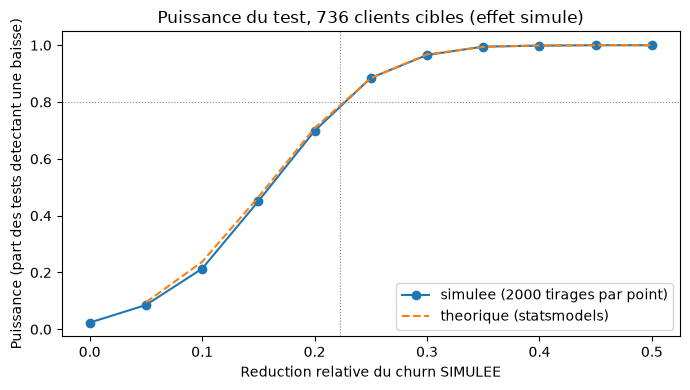

,reduction_simulee,puissance_simulee,puissance_theorique
0,0.0000,0.0235,NaN
1,0.0500,0.0855,0.0950
2,0.1000,0.2135,0.2375
3,0.1500,0.4510,0.4652
4,0.2000,0.6985,0.7084
5,0.2500,0.8850,0.8836
6,0.3000,0.9655,0.9677
7,0.3500,0.9950,0.9941
8,0.4000,0.9985,0.9993
9,0.4500,1.0000,1.0000


In [9]:
grid = np.round(np.arange(0.0, 0.51, 0.05), 2)
power_curve = pd.DataFrame({
    "reduction_simulee": grid,
    "puissance_simulee": [ab.simulated_power(y, r, N_SIMS, SEED_POWER, ALPHA) for r in grid],
    "puissance_theorique": [ab.theoretical_power(P_BASE, r, n_per_group, ALPHA) if r > 0 else np.nan
                            for r in grid],
})

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid, power_curve["puissance_simulee"], "o-", label=f"simulee ({N_SIMS} tirages par point)")
ax.plot(grid, power_curve["puissance_theorique"], "--", label="theorique (statsmodels)")
ax.axhline(POWER, color="grey", lw=0.8, ls=":")
ax.axvline(mde["relative_reduction"], color="grey", lw=0.8, ls=":")
ax.set_xlabel("Reduction relative du churn SIMULEE")
ax.set_ylabel("Puissance (part des tests detectant une baisse)")
ax.set_title(f"Puissance du test, {N_TARGET} clients cibles (effet simule)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "ab_power_curve.png", dpi=120)
plt.show()
display(power_curve)

In [10]:
p10 = power_curve.loc[power_curve["reduction_simulee"] == 0.10, "puissance_simulee"].iloc[0]
r10 = results.loc[results["reduction_simulee"] == 0.10].iloc[0]
print(f"Effet simule de 10 % : p = {r10['p_value']:.3f} sur ce tirage ; "
      f"puissance simulee {p10:.1%} (environ {1 - p10:.0%} des experiences ne le detecteraient pas).")

Effet simule de 10 % : p = 0.149 sur ce tirage ; puissance simulee 21.3% (environ 79% des experiences ne le detecteraient pas).


**Lecture de l'effet de 10 %.** Avec cet effectif, une vraie baisse de 10 %
n'est detectee que dans une minorite d'experiences. Un resultat non
significatif a 10 % est donc un **manque de puissance**, pas la preuve que
la campagne est sans effet : l'effet simule existe, par construction, et le
test ne peut pas le voir. Seuls les effets autour de l'effet minimal
detectable ou au-dessus (section 3) sont detectes avec une puissance proche
de 80 %.

## 8. Garde-fou : cout de la campagne (hypotheses du projet)

Hypotheses de la matrice de couts du projet, **pas des montants mesures** :
cout d'une action et perte associee a un client parti, en unites
monetaires du projet. Formules :

- cout de la campagne = clients traites x cout d'une action
- churners evites (esperance) = clients traites x churn de base x reduction relative
- benefice net attendu = churners evites x perte par client - cout de la campagne
- seuil de rentabilite : reduction relative > cout d'une action / (churn de base x perte par client)

Ce sont des **calculs sous hypotheses** sur un effet **simule**, jamais un
gain constate.

In [11]:
n_treated = int(treated.sum())
print(f"Hypotheses : action {COSTS['action_cost']:.0f}, client perdu {COSTS['churn_loss']:.0f} "
      f"(models/serving_config.json)")
print(f"Cout du test (groupe traite) : {n_treated} x {COSTS['action_cost']:.0f} = "
      f"{ab.campaign_cost(n_treated, COSTS['action_cost']):,.0f}")
benefit = pd.DataFrame([{"reduction_simulee": r,
                         **ab.expected_net_benefit(n_treated, P_BASE, r, COSTS["action_cost"],
                                                   COSTS["churn_loss"])}
                        for r in SIMULATED_EFFECTS])
print(f"Seuil de rentabilite (hypotheses) : reduction relative > "
      f"{COSTS['action_cost']:.0f} / ({P_BASE:.4f} x {COSTS['churn_loss']:.0f}) = "
      f"{benefit['break_even_relative_reduction'].iloc[0]:.1%} "
      f"(effet minimal detectable : {mde['relative_reduction']:.1%})")
display(benefit[["reduction_simulee", "n_treated", "avoided_churners", "campaign_cost", "avoided_loss",
         "net_benefit"]])

Hypotheses : action 50, client perdu 500 (models/serving_config.json)
Cout du test (groupe traite) : 365 x 50 = 18,250
Seuil de rentabilite (hypotheses) : reduction relative > 50 / (0.4538 x 500) = 22.0% (effet minimal detectable : 22.3%)


,reduction_simulee,n_treated,avoided_churners,campaign_cost,avoided_loss,net_benefit
0,0.0000,365,0.0000,"18,250.0000",0.0000,"-18,250.0000"
1,0.1000,365,16.5639,"18,250.0000","8,281.9293","-9,968.0707"
2,0.2000,365,33.1277,"18,250.0000","16,563.8587","-1,686.1413"
3,0.3000,365,49.6916,"18,250.0000","24,845.7880","6,595.7880"
4,0.5000,365,82.8193,"18,250.0000","41,409.6467","23,159.6467"


A comparer avec l'effet minimal detectable de la section 3. S'ils sont du meme ordre,
le test ne distinguerait de facon fiable qu'une campagne deja rentable
sous ces hypotheses.

## 9. Mauvaises pratiques a eviter

- **Regarder les resultats trop tot** et decider sur un resultat
  intermediaire : la taille d'echantillon est fixee avant, l'analyse a lieu a la fin.
- **Arreter des que c'est significatif** : en testant a chaque nouvel
  arrivage, on finit par tomber sur p < 0,05 par hasard (le taux de faux positifs explose).
- **Multiplier les metriques sans correction** : avec 20 metriques a 5 %,
  environ une sera significative par hasard ; une metrique principale, les autres corrigees (Bonferroni, Holm).
- **Ignorer un ecart de ratio (SRM) ou un desequilibre** : l'effet mesure
  pourrait venir de l'assignation, pas de la campagne.

## 10. Conclusion

**Ce que le notebook montre** : la demarche complete d'un test A/B sur le
churn des clients cibles par le modele : hypotheses fixees avant, calcul de
la taille d'echantillon et de l'effet minimal detectable, randomisation
verifiee (ratio et equilibre), test A/A qui confirme un taux de faux
positifs proche de 5 %, test de deux proportions avec intervalle de
confiance, puissance simulee et garde-fou de cout.

**Ce qu'il ne montre pas** : l'efficacite d'une campagne. **L'effet est
simule**, par construction ; aucun client n'a ete contacte. Les chiffres
de benefice sont des calculs sous les hypotheses de cout du projet, pas
des gains.

**Limites** :
- effet simule, avec une hypothese simple (chaque churner retenu avec la
  meme probabilite, aucun effet negatif) ;
- jeu public IBM Telco, photographie statique : le label « churn » n'est
  pas un churn futur observe apres une campagne ;
- un seul tirage de randomisation pour l'analyse principale (la puissance
  simulee couvre la variabilite entre tirages), sans stratification : un
  leger desequilibre peut subsister (section 4) ;
- effectif limite au groupe cible du jeu de test (environ la moitie par
  groupe, chiffres ci-dessous) : seuls les effets importants sont
  detectables ; un vrai test demanderait plus de clients ou plus de temps.

In [12]:
print("Chiffres de cette execution :")
print(f"- groupe cible : {N_TARGET} clients, {y.sum()} churners, churn de base {P_BASE:.2%}")
print(f"- effet minimal detectable : reduction relative de {mde['relative_reduction']:.1%} "
      f"({n_per_group} clients par groupe)")
print(f"- taux de faux positifs du test A/A : {aa['rate']:.2%} sur {N_SIMS} tirages")
for _, row in results.iterrows():
    print(f"- effet SIMULE {row['reduction_simulee']:.0%} : churn {row['rate_control']:.1%} -> "
          f"{row['rate_treatment']:.1%}, p = {row['p_value']:.4f}, "
          f"{'significatif' if row['significant'] else 'non significatif'}")
print(f"Temps d'execution du notebook : {time.time() - T0:.1f} s")

Chiffres de cette execution :
- groupe cible : 736 clients, 334 churners, churn de base 45.38%
- effet minimal detectable : reduction relative de 22.3% (368 clients par groupe)
- taux de faux positifs du test A/A : 5.00% sur 2000 tirages
- effet SIMULE 0% : churn 45.8% -> 44.9%, p = 0.8083, non significatif
- effet SIMULE 10% : churn 45.8% -> 40.5%, p = 0.1487, non significatif
- effet SIMULE 20% : churn 45.8% -> 37.3%, p = 0.0185, significatif
- effet SIMULE 30% : churn 45.8% -> 33.2%, p = 0.0004, significatif
- effet SIMULE 50% : churn 45.8% -> 21.9%, p = 0.0000, significatif
Temps d'execution du notebook : 1.0 s
